# GS-000: Coordinate-Wise Additivity — Reviewer Companion

**AuthorityEffect: None.**  
**Publication:** canonical v6.1.1; this companion belongs to the unpublished repository draft.

Two reading tracks pair mathematical proofs with examples and analogies.
Physical analogies illustrate declared observer assumptions; they supply no empirical evidence.
The code probes specified finite inputs. Passing a probe does not prove a universal axiom.
Theorems 1–3 have prose proofs; the historical Lean receipt covers narrower declarations.



In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Path bootstrapping to locate the code package
def _find_package_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "jupyter_notebooks").is_dir():
            return candidate
    raise RuntimeError("Package root not found from the current working directory")

pkg_root = _find_package_root(Path.cwd().resolve())
module_dir = pkg_root / "code"
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

from coord_additivity import (
    coord_l1, coord_l2, coord_linf, anisotropic_l1,
    theorem1_weight, theorem1_predict, theorem1_holds,
    EdgeOrbitDiagnostic, uniform_collapse,
    ce1_l2_fails_additivity, ce2_anisotropic_fails_symmetry, ce3_cross_edge_fails_locality, ce3_max_fails_additivity,
    ce4_orbit_weights_do_not_collapse, ce5_lp_power_fails_homogeneity,
)
from cohomology_quotients import (
    DirectedGraph, coboundary_d0, is_coboundary, lggr_obstruction_witness,
)
from gauge_holonomy import (
    CellComplex2D, Plaquette, U1GaugeField, evaluate_u1_flux_l1,
)
from quantum_schatten import (
    schatten_norm, trace_norm, are_mutually_orthogonal_support,
    quantum_state_trace_distance, cptp_depolarizing_channel,
)

try:
    import ipywidgets as W
    from IPython.display import display, clear_output
    HAS_WIDGETS = True
except Exception:
    HAS_WIDGETS = False

print(f"GS-000 Master Engine Initialized | Interactive Widgets: {HAS_WIDGETS}")


GS-000 Master Engine Initialized | Interactive Widgets: True


## 1. Theorem 1: Edgewise $\ell^1$ Selection

### 🟢 Track A: The Pipe Joint Analogy (Intuition)
Imagine an industrial pipe manifold with $k$ independent valves. Each valve $i$ has an individual fluid leak of magnitude $x_i$.
- If the leak channels are **physically separate** (disjoint support), the total fluid escaping into the room is simply $|x_1| + |x_2| + \dots + |x_k|$.
- Why not Euclidean root-sum-squares $\sqrt{x_1^2 + x_2^2}$? Because the Euclidean metric assumes rotational invariance! In Euclidean space, rotating a leak by 45 degrees claims that Valve 1 can 'cancel out' or 'couple with' Valve 2. When channels are genuinely independent, only $\ell^1$ linear addition respects this independence.

### 🔵 Track B: Formal Proof (Rigor)
Let $x = \sum_{i=1}^k x_i e_i \in \mathbb{R}^k$. By Disjoint-Coordinate Additivity (**H3**):
$$\nu_e(x) = \sum_{i=1}^k \nu_e(x_i e_i)$$
By Absolute Homogeneity (**H5**):
$$\nu_e(x_i e_i) = |x_i| \nu_e(e_i)$$
By Coordinate Permutation Symmetry (**H2**), $\nu_e(e_i) = \nu_e(e_1) =: w_e$ for all $i$. Therefore:
$$\nu_e(x) = w_e \sum_{i=1}^k |x_i| = w_e \|x\|_1$$
*Lean 4 Proof:* Mechanized in `PaperGS003.coord_real_l1_weighted_sum` and `coord_real_l1_exists_scalar_succ`.

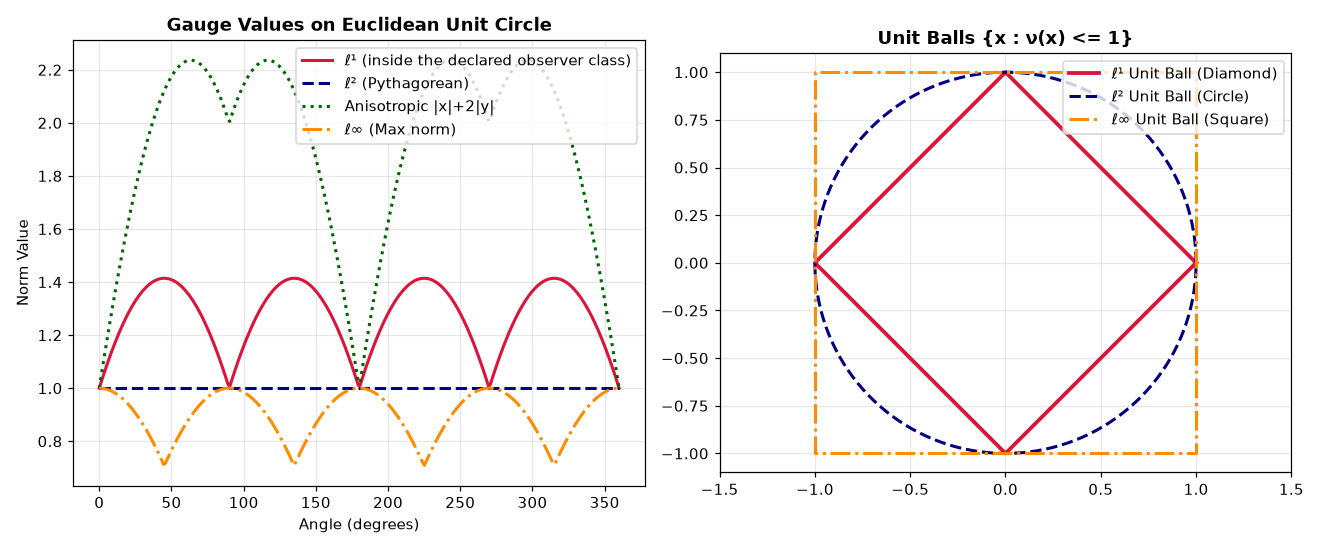

In [2]:
# Visualizing the Geometry of Different Observer Gauges in 2D
theta = np.linspace(0, 2 * np.pi, 300)
circle_pts = np.stack([np.cos(theta), np.sin(theta)], axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: Value of each gauge on Euclidean unit circle
ax1.plot(np.degrees(theta), [coord_l1(p) for p in circle_pts], label="ℓ¹ (inside the declared observer class)", lw=2, color="crimson")
ax1.plot(np.degrees(theta), [coord_l2(p) for p in circle_pts], label="ℓ² (Pythagorean)", lw=2, color="navy", ls="--")
ax1.plot(np.degrees(theta), [anisotropic_l1(p, (1.0, 2.0)) for p in circle_pts], label="Anisotropic |x|+2|y|", lw=2, color="darkgreen", ls=":")
ax1.plot(np.degrees(theta), [coord_linf(p) for p in circle_pts], label="ℓ∞ (Max norm)", lw=2, color="darkorange", ls="-.")
ax1.set_title("Gauge Values on Euclidean Unit Circle", fontsize=12, fontweight="bold")
ax1.set_xlabel("Angle (degrees)")
ax1.set_ylabel("Norm Value")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Right: Unit Balls {x : ||x|| <= 1}
# l1 unit ball: diamond
ax2.plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], label="ℓ¹ Unit Ball (Diamond)", color="crimson", lw=2.5)
# l2 unit ball: circle
ax2.plot(np.cos(theta), np.sin(theta), label="ℓ² Unit Ball (Circle)", color="navy", ls="--", lw=2)
# l_inf unit ball: square
ax2.plot([1, -1, -1, 1, 1], [1, 1, -1, -1, 1], label="ℓ∞ Unit Ball (Square)", color="darkorange", ls="-.", lw=2)
ax2.set_title("Unit Balls {x : ν(x) <= 1}", fontsize=12, fontweight="bold")
ax2.set_xlim(-1.5, 1.5)
ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


## 2. Theorems 2 & 3: Network Aggregation and Edge-Uniformity

### 🟢 Track A: Highways vs Country Lanes (Intuition)
Across an entire network (like a road graph):
- Symmetries (automorphisms) group edges into **orbits**. For instance, all 4-lane interstate highways look structurally identical, while all 1-lane dirt roads form another class.
- Graph symmetry forces every highway edge to have the exact same weight $w_{\text{highway}}$.
- But can we add highways and dirt roads with the **exact same scalar weight**? **No!** That requires an extra assumption: **Edge-Uniformity** (or edge-transitivity).

### 🔵 Track B: Theorems 2 & 3 Formulations (Rigor)
- **Theorem 2 (Orbit-Weighted $\ell^1$):** Under $\Gamma \le \mathrm{Aut}(G)$, the edge set partitions into orbits $E = \bigsqcup_{\mathcal{O}} \mathcal{O}$. Then:
  $$\nu_G(\delta) = \sum_{\mathcal{O}} w_{\mathcal{O}} \sum_{e \in \mathcal{O}} \|\delta_e\|_1$$
- **Theorem 3 (Edge-Uniformity Collapse):** If all orbits share a single scalar weight $w_{\mathcal{O}} = \alpha$, then:
  $$\nu_G(\delta) = \alpha \sum_{e \in E} \|\delta_e\|_1 = \alpha \|\delta\|_{\ell^1(E \times \{1,\dots,k\})}$$
*Worked Replay:* Below we compute a 2-edge cochain with orbit weights $w_1 = 1.0$ and $w_2 = 2.0$.

In [3]:
# Worked Replay from Section 2.4 of the Paper
delta_e1 = np.array([3.0, -4.0])
delta_e2 = np.array([1.0, 2.0])

diag = EdgeOrbitDiagnostic(orbit_of_edge=(0, 1), orbit_weights=(1.0, 2.0))
orbit_weighted_total = diag.total([delta_e1, delta_e2])
unweighted_total = coord_l1(delta_e1) + coord_l1(delta_e2)

print("=== WORKED REPLAY ===")
print(f"Edge 1 vector: {delta_e1} -> |3| + |-4| = {coord_l1(delta_e1)}")
print(f"Edge 2 vector: {delta_e2} -> |1| + |2|  = {coord_l1(delta_e2)}")
print(f"Orbit-Weighted Total (w1=1, w2=2): {orbit_weighted_total} (Expected: 13.0)")
print(f"Unweighted Total (alpha=1):        {unweighted_total} (Expected: 10.0)")
assert orbit_weighted_total == 13.0
assert unweighted_total == 10.0


=== WORKED REPLAY ===
Edge 1 vector: [ 3. -4.] -> |3| + |-4| = 7.0
Edge 2 vector: [1. 2.] -> |1| + |2|  = 3.0
Orbit-Weighted Total (w1=1, w2=2): 13.0 (Expected: 13.0)
Unweighted Total (alpha=1):        10.0 (Expected: 10.0)


## 3. Boundary Counterexamples and Exact Evidence Scope

CE1–CE3 target H3, H2, and H1; CE4 targets additional edge-uniformity.
CE5 changes the standing seminorm premise as well as homogeneity.
It is inaccurate to say that these are five independent removals from H1–H5.

| Case | Prose witness | Shipped Lean declaration and limit |
|---|---|---|
| CE1: remove H3 | Real Euclidean norm, k≥2 | `ce1_quadratic_not_l1_scalar`: natural-number quadratic, not the Euclidean norm |
| CE2: remove H2 | Unequal coordinate weights, trivial fiber transport | `ce2_weighted_l1_not_uniform`: arithmetic weight witness |
| CE3: remove H1 | Real seminorm $|a+b|$ permits cancellation | `ce3_cross_edge_coupling_not_edge_local`: natural-number coupled polynomial |
| CE4: remove edge-uniformity | Distinct edge-orbit weights | `ce4_orbit_weighted_not_unweighted`: arithmetic non-collapse witness |
| CE5: weaken seminormhood, remove H5 | Candidate $sum_i|x_i|^p$, 0<p<1 | `ce5_lp_not_homogeneous`: p=2 over naturals; outside the subadditive candidate range |

The historical receipt verifies only those exact declarations. The broader CE5
formalization remains OPEN / NOT_VERIFIED. The max norm is an additional H3
example, not manuscript CE3. At p=2 the power gauge also loses subadditivity:
$Phi(2,0)=4>2=Phi(1,0)+Phi(1,0)$.


In [4]:
print("=== FINITE COUNTEREXAMPLE PROBES ===")
assert ce1_l2_fails_additivity()
assert ce2_anisotropic_fails_symmetry()
assert ce3_cross_edge_fails_locality()
assert ce3_max_fails_additivity()  # additional H3 witness, legacy API name
assert ce4_orbit_weights_do_not_collapse()
assert ce5_lp_power_fails_homogeneity(p=0.5)
print("CE1: Euclidean l2 violates H3; CE2: unequal coordinate weights violate H2")
print("CE3: |1 + (-1)| = 0, while |1| + |-1| = 2; H1 fails")
print("Additional H3 witness: max(1, 1) = 1 < 2")
print("CE4: unit-edge probes infer weights 1 and 2, so no shared scalar")
print("CE5: p=0.5 finite scaling probe fails H5; this does not close the full formalization")


=== FINITE COUNTEREXAMPLE PROBES ===
CE1: Euclidean l2 violates H3; CE2: unequal coordinate weights violate H2
CE3: |1 + (-1)| = 0, while |1| + |-1| = 2; H1 fails
Additional H3 witness: max(1, 1) = 1 < 2
CE4: unit-edge probes infer weights 1 and 2, so no shared scalar
CE5: p=0.5 finite scaling probe fails H5; this does not close the full formalization


## 4. Optional Extensions and Quotient Boundaries

### Extension 1: Keep the carrier and relation explicit

For a graph viewed as a one-dimensional complex (no attached 2-cells),
$C^1/operatorname{im}(d_0)$ describes first cohomology. In a complex with 2-cells,
first cohomology instead uses $ker(d_1)/operatorname{im}(d_0)$.
This linear quotient differs from equality of seminorm readouts.

For fixed weights, identical per-edge values always produce identical weighted
totals. Nonuniformity does not block that descent. Two separate comparisons can
lose information: equal **unweighted totals** may conceal distribution across
edges, and **varying-profile records** may conceal weights. The next cell checks
all three cases separately. The broader cross-graph LGGR interpretation remains open.


In [5]:
witness = lggr_obstruction_witness()
print("=== THREE DISTINCT QUOTIENT COMPARISONS ===")
assert witness["local_green"] and witness["fixed_profile_global_equal"]
assert witness["fixed_profile_total_1"] == witness["fixed_profile_total_2"] == 13.0
print("Fixed weights, same per-edge values: 13 = 13; descent holds")

assert witness["unweighted_equal"] and not witness["coarse_pair_per_edge_equal"]
assert witness["orbit_total_a"] == 13.0 and witness["orbit_total_b"] == 17.0
print("Same unweighted total 10, different per-edge values: weighted totals 13 and 17")

assert witness["varying_profile_total_1"] == 13.0
assert witness["varying_profile_total_2"] == 20.0
print("Same cochain, changed profile (1,2) -> (2,2): totals 13 and 20")


=== THREE DISTINCT QUOTIENT COMPARISONS ===
Fixed weights, same per-edge values: 13 = 13; descent holds
Same unweighted total 10, different per-edge values: weighted totals 13 and 17
Same cochain, changed profile (1,2) -> (2,2): totals 13 and 20


### Extension 2: Imported Operator Models and the Trace Norm

These matrices are a separate representation model, not a consequence of the
finite graph theorem. Orthogonal left and right supports satisfy
$AB^dagger=0$ and $A^dagger B=0$, the operator analogue of disjoint support.
The trace norm is the sum of singular values. A uniqueness classification
requires a seminorm premise, homogeneity, and the appropriate finite-dimensional
unitary and orthogonal-additivity hypotheses; plotting or replaying examples does not prove it.

Trace distance is **non-increasing** under CPTP channels; strict decrease does not
hold for every channel (the identity channel preserves it). The next cell only
tests the explicit depolarizing example at p=0.35 and the identity case p=0.


In [6]:
# Quantum Operator Experiment
rho = np.array([[1.0, 0.0], [0.0, 0.0]], dtype=complex)
sigma = np.array([[0.0, 0.0], [0.0, 1.0]], dtype=complex)

d_initial = quantum_state_trace_distance(rho, sigma)
print(f"Initial Trace Distance between orthogonal states: {d_initial}")

# Apply CPTP depolarizing noise (p = 0.35)
rho_noisy = cptp_depolarizing_channel(rho, p=0.35)
sigma_noisy = cptp_depolarizing_channel(sigma, p=0.35)
d_contracted = quantum_state_trace_distance(rho_noisy, sigma_noisy)

print(f"Contracted Trace Distance after noise:             {d_contracted:.4f}")
print("CPTP Contractivity Verified?                      ", d_contracted < d_initial)
assert np.isclose(d_initial, 1.0)
assert np.isclose(d_contracted, 0.65)
assert np.isclose(quantum_state_trace_distance(
    cptp_depolarizing_channel(rho, 0.0),
    cptp_depolarizing_channel(sigma, 0.0)), d_initial)


Initial Trace Distance between orthogonal states: 1.0
Contracted Trace Distance after noise:             0.6500
CPTP Contractivity Verified?                       True
